# Week 7b.1: Multi-Agent Orchestration: The Supervisor Pattern

In the previous class, we built a research team in which several workers searched the literature in parallel and a lead agent combined their findings into a report. Every question went through the same steps: plan, search, write.

A research assistant receives more than one kind of request:

- "Which paper introduced the MAST taxonomy?" needs a search, and nothing more.
- "Summarize what is known about why multi-agent systems fail." needs a search, a written report, and a review of that report.
- "Check this claim: multi-agent debate improves accuracy on GSM8K." needs no new report at all, only a check of the claim against the papers.

A fixed pipeline handles these badly. It either runs every step for every request, which wastes time and model calls on a simple lookup, or it cannot handle the request at all, as with the claim that needs checking rather than writing.

In this notebook, we'll build a **supervisor**: an agent that reads the request, decides which specialist agents it needs, and calls them one at a time, deciding again after each one reports back. We will use three specialist agents:

- **Researcher**: Searches the papers and returns findings. This is the team we built in W07a.
- **Writer**: Writes a report from the findings and checks its citations.
- **Reviewer**: Checks a report, or a claim in the request, against the literature, and reports what is missing.

The agents never call each other. Each one does its job and reports back to the supervisor, which decides what runs next.




The supervisor's first decision depends on the request:
- A request for a specific paper needs only the researcher.
- A request for a summary needs the researcher, then the writer, then the reviewer.
- A request to check a claim needs only the reviewer.

After each agent reports back, the supervisor decides again. 
- When the reviewer finds a gap in a report, the supervisor sends the researcher or the writer back to close it. 
- Each decision is one model call.

In [1]:
from dotenv import load_dotenv
import os

load_dotenv()
assert os.getenv("GOOGLE_API_KEY"), "No GOOGLE_API_KEY found."
print("API key loaded")

API key loaded


## 0. Model Setup

Execute one of the following to define the model.

In [2]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="qwen3.5:4b", reasoning=False, num_ctx=16384)

In [ ]:
from langchain.chat_models import init_chat_model

model = init_chat_model(model="gpt-4.1-mini")

In [ ]:
from langchain.chat_models import init_chat_model

model = init_chat_model(model="claude-haiku-5-5")

In [29]:
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

## 1. Multi-Agent Team

The multi-agent team we built in W07a is in `research_team.py`.
- `build_team` has the same code and expect to receive the model as an argument. 

The tools are in `research_tools.py` and the papers in `papers.json`, as before.

In [30]:
import research_tools as rt
import research_team as team
import time

QUESTION = list(rt.questions())[0]
GOLD = rt.questions()[QUESTION]["gold"]
print(QUESTION)

Why do multi-agent LLM systems fail, and what has been proposed to make them more reliable?


## 2. The agents

Each agent reads one kind of thing and produces another, and the state carries them between agents:
- The researcher produces **findings**: a list of (sub-question, text) pairs.
- The writer produces a **report**, and the list of citations that failed its check.
- The reviewer produces a **verdict** and a **note** saying what is missing.

In [31]:
import operator
from typing import Annotated, Literal, TypedDict
from pydantic import BaseModel, Field
from langchain.messages import HumanMessage
from langgraph.graph import StateGraph, START, END


class TeamState(TypedDict):
    question: str
    findings: Annotated[list, operator.add]   # from the researcher; each run adds to it
    report: str                               # from the writer
    unsupported: list                         # from the writer's citation check: ids that did not hold up
    review: str                               # from the reviewer: accept, research, or rewrite
    gap: str                                  # from the reviewer: what is missing
    next: str                                 # from the supervisor: who runs next
    decisions: Annotated[int, operator.add]   # from the supervisor: how many times it has decided
    tokens: Annotated[int, operator.add]
    log: Annotated[list, operator.add]        # who ran, in order

Four fields have the `operator.add` reducer:
- `findings`: the researcher can run more than once. The second run adds findings for the gap instead of replacing the first run's findings.
- `decisions`: the supervisor adds 1 each time it decides. The graph stops the run when it reaches a cap.
- `tokens` and `log`: each agent adds what it spent and its name.

### The researcher

- The researcher agent is the same plan-and-workers team from Tuesday, which will stop before the synthesis
    - It only produces findings
    - Writing is someone else's job now
- On the first run it researches the question
- When the reviewer's verdict is `research`, it researches the gap the reviewer named

In [32]:
researcher_graph = team.build_team(model, with_report=False)


def researcher(state: TeamState) -> dict:
    topic = state["gap"] if state.get("review") == "research" else state["question"]
    result = researcher_graph.invoke({"question": topic, "findings": [], "tokens": 0}) #TODO invoke the research agent with topic
    return {"findings": result["findings"], "tokens": result["tokens"], "log": ["researcher"]}

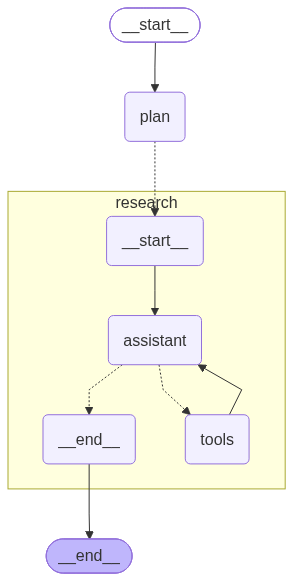

In [33]:
from IPython.display import Image, display

display(Image(researcher_graph.get_graph(xray=True).draw_mermaid_png()))


### The writer

The writer is a ReAct agent, built with `team.build_agent`. Its one tool is `get_paper`, so it can read a paper before it says what the paper found.

The writer does two things before it reports back:
1. It writes a draft from the findings.
2. It checks every citation in the draft. If any fail, it gets one chance to fix them.

The check is the grader pattern from W05b. It works here because the checker sees something the writer did not write: the papers' abstracts.

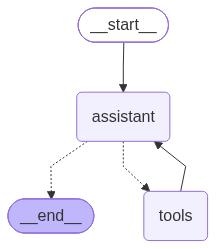

In [34]:
WRITER_SYSTEM = """You write research reports from findings that other agents have gathered.
Before you state what a paper found, you may read it with get_paper. Cite only papers
that appear in the findings, with the paper id in brackets after each claim, like [2503.13657]."""


writer_agent = team.build_agent(model, WRITER_SYSTEM, tools=[rt.get_paper])# TODO define the writer agent: model, prompt, tools

display(Image(writer_agent.get_graph().draw_mermaid_png()))


#### The citation check

For every id the report cites, the check answers two questions:
- Does the paper exist?
    - That is a lookup.
- Does its abstract support the sentences that cite it?
    - That is a model call per sentence, with a structured yes-or-no.

We build it in four steps and run each one on a short sample report.

#### Step 1: finding the cited ids

`rt.found_ids(text)` returns every paper id in a piece of text. 

An arXiv id is four digits, a dot, and four or five digits, as in `2503.13657`. 
- The function finds that pattern with a regular expression,
- Accepts the forms a model tends to write even when it is asked for brackets: 
    - `[2503.13657]`, `[arXiv:2503.13657]`,
    - an id with a version suffix such as `v2`, and 
    - an id with no brackets at all. 

It returns each id once in a sorted list.

In [35]:
sample = ("MAST groups failures into three categories [2503.13657]. "
          "AutoGen lets agents talk to each other [arXiv:2308.08155]. "
          "CAMEL uses role-play (2303.17760v2). "
          "A made-up paper is cited here [2501.99999]. "
          "MAST is cited again [2503.13657].")

print(sample)

MAST groups failures into three categories [2503.13657]. AutoGen lets agents talk to each other [arXiv:2308.08155]. CAMEL uses role-play (2303.17760v2). A made-up paper is cited here [2501.99999]. MAST is cited again [2503.13657].


In [36]:
rt.found_ids(sample)

['2303.17760', '2308.08155', '2501.99999', '2503.13657']

Four ids, each listed once, whichever way it was written. 

The last one, `2501.99999`, is not in our paper file. 

**Checking that a cited paper exists is the first thing the check does.**

#### Step 2: splitting the report into sentences

To check a citation, the check needs the sentence that makes the claim. 

`sentences_citing` splits the report into sentences and keeps the ones that contain the paper id.

The split uses the regular expression `(?<=[.!?])\s+`:

- `\s+` matches one or more whitespace characters: the space or line break between two sentences.
- `(?<=[.!?])` is a *lookbehind*. It matches no characters itself. It only requires that the character just before the whitespace is `.`, `!` or `?`.

Together they match the whitespace that follows the end of a sentence. 

`re.split` cuts the text there, and because the punctuation is not part of the match, each sentence keeps its period.

In [37]:
import re

re.split(r"(?<=[.!?])\s+", sample)

['MAST groups failures into three categories [2503.13657].',
 'AutoGen lets agents talk to each other [arXiv:2308.08155].',
 'CAMEL uses role-play (2303.17760v2).',
 'A made-up paper is cited here [2501.99999].',
 'MAST is cited again [2503.13657].']

Now we need to keep only the sentences that cite a given id. 

The test is `paper_id in s`, which finds the id however the sentence writes it: `[2308.08155]`, `[arXiv:2308.08155]`, or `2308.08155v2`.

In [38]:
def sentences_citing(report, paper_id):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", report) if paper_id in s]


print(sentences_citing(sample, "2503.13657"))
print(sentences_citing(sample, "2308.08155"))

['MAST groups failures into three categories [2503.13657].', 'MAST is cited again [2503.13657].']
['AutoGen lets agents talk to each other [arXiv:2308.08155].']


#### Step 3: checking one citation

The check is the grader pattern from W05b: a structured output with the reasoning written before the verdict. 

Every paper in `papers.json` is a dictionary with fields such as `title`, `authors` and `abstract`. 
- `rt.cache()["papers"]` holds them all, keyed by id. The check sends the paper's `abstract`.

`check` can return three values:

- `True`: the abstract is consistent with the sentence.
- `False`: the paper is about something else, or the abstract says the opposite.
- `None`: the model did not return the structure. That is a failure of the checker, not evidence against the citation, so the check does not count it as unsupported.

The prompt asks for consistency rather than proof on purpose.

In [39]:
class Supported(BaseModel):
    """Whether one abstract supports one sentence."""
    reasoning: str = Field(description="one sentence: what the abstract says about the claim")
    supported: bool


checker = model.with_structured_output(Supported)  #TODO add the structured output constraint to the model

CHECK_PROMPT = """A report says: "{sentence}"

It cites a paper whose abstract is:

{abstract}

Is the sentence consistent with this paper? Consistent means the paper is
about this subject and nothing in the abstract contradicts the sentence. Only
answer no when the paper is about something else, or the abstract says the
opposite. One sentence of reasoning, then yes or no."""


def check(sentence, abstract):
    """"Check one sentence against one abstract.

    Returns True if the abstract is consistent with the sentence, False if it is not,
    and None if the model did not return a valid answer."""
    try:
        return checker.invoke(CHECK_PROMPT.format(sentence=sentence, abstract=abstract)).supported
    except Exception:
        return None

Let's try it on two sentences that cite the same paper: one the abstract supports and one about a different subject.

In [40]:
papers = rt.cache()["papers"]
abstract = papers["2503.13657"]["abstract"]
print(abstract[:300], "...\n")

print(check("MAST builds a taxonomy of the ways multi-agent LLM systems fail [2503.13657].", abstract))
print(check("MAST introduces a method for compressing images [2503.13657].", abstract))

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


Despite enthusiasm for Multi-Agent LLM Systems (MAS), their performance gains on popular benchmarks are often minimal. This gap highlights a critical need for a principled understanding of why MAS fail. Addressing this question requires systematic identification and analysis of failure patterns. We  ...

True
False


#### Step 4: the whole check

`check_citations` puts the three steps together. For each id the report cites:

1. Look the paper up. If there is no such paper, the citation fails, and no model call is needed.
2. Find every sentence that cites it.
3. Check each sentence against the paper's abstract. If a check returns `False`, the citation fails, and the remaining sentences for that paper are skipped.

It returns the failed ids, sorted and without repeats.

In [41]:
def check_citations(report):
    unsupported = []
    for paper_id in rt.found_ids(report):
        paper = papers.get(paper_id)
        if paper is None:
            unsupported.append(paper_id)          # a citation to nothing
            continue
        for sentence in sentences_citing(report, paper_id):
            if check(sentence, paper["abstract"]) is False:
                unsupported.append(paper_id)      # one bad claim is enough
                break
    return unsupported


check_citations(sample)

['2501.99999']

#### The writer with citation check
On the first pass, the writer's task is the question and the findings. When the reviewer sends a report back with the verdict `rewrite`, `fixes_for` adds the reviewer's note to the task.

After the draft, the writer node runs `check_citations`. If any citation fails, the writer gets the failed ids and one chance to fix them, and the check runs again. Whatever still fails is reported in `unsupported`, so the supervisor and the reviewer can see it.

In [42]:
WRITER_PROMPT = """Question: {question}

Findings from the researchers:

{findings}

Write the report: what is known, organized by the parts of the question, with
every claim followed by the paper id in brackets as the findings give it. Do
not add papers the findings did not cite.
{fixes}"""


FIX_PROMPT = """These citations in your report did not hold up when checked against the
papers' abstracts: {ids}.

Findings from the researchers:

{findings}

Report:

{report}

Rewrite the report so that every claim is supported. Cite a paper from the findings
that supports the claim, or drop the claim. Return only the corrected report, starting
with its title. Do not describe what you changed."""

In [43]:
def fixes_for(state: TeamState) -> str:
    """Return extra instructions for the writer's task: the reviewer's note when
    the verdict is rewrite, and an empty string otherwise."""
    if state.get("review") == "rewrite":
        return "\nA reviewer said this is missing; address it: " + state["gap"]
    return ""

def writer(state: TeamState) -> dict:
    findings = team.format_findings(state["findings"])

    # draft report
    task = WRITER_PROMPT.format(question=state["question"], findings=findings, fixes=fixes_for(state)) #TODO format writer prompt with question, findings, fixes
    messages = writer_agent.invoke({"messages": [HumanMessage(content=task)]})["messages"]
    report, tokens = messages[-1].text, team.tokens_of(messages)

    # citation check
    unsupported = check_citations(report) #TODO get the list of unsupported citations
    if unsupported:                               # one chance to fix what failed
        fix = FIX_PROMPT.format(ids=", ".join(unsupported), findings=findings, report=report)
        
        messages = writer_agent.invoke({"messages": [HumanMessage(content=fix)]})["messages"]
        report, tokens = messages[-1].text, tokens + team.tokens_of(messages)
        
        unsupported = check_citations(report)

    return {"report": report, "unsupported": unsupported, "tokens": tokens, "log": ["writer"]}

### The reviewer

The reviewer is also a ReAct agent. Its tools are `search_papers` and `get_paper`, so it does not have to guess: it searches the literature itself.

It has two tasks, depending on what it is given:
- **A report**: it checks whether the report answers every part of the question, and searches for the parts it does not cover.
- **No report**, as when the request is to check a claim: it checks the claim against the literature.

The reviewer works in two steps:
1. The agent reads its task, searches, and writes its review as text.
2. A structured-output call turns that review into a verdict and a note.

The verdict has three values:
- `accept`: the report answers every part of the question, or the papers settle the claim.
- `research`: a missing part needs papers that the researchers have not found yet.
- `rewrite`: the papers are already in the findings, but the report does not use them.

To tell `research` from `rewrite`, the reviewer is given the ids of the papers the researchers have already found.

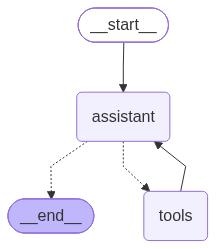

In [44]:
REVIEWER_SYSTEM = """You review research reports. Read the question and the report. Then search
the literature with search_papers for any part of the question the report does not cover,
and read promising papers with get_paper. Be specific: name the missing part, and the
paper ids that cover it."""

reviewer_agent = team.build_agent(model, REVIEWER_SYSTEM, tools=[rt.search_papers, rt.get_paper])   #TODO: build the reviwer agent

display(Image(reviewer_agent.get_graph().draw_mermaid_png()))



In [45]:
class Review(BaseModel):
    """The reviewer's verdict on the report."""
    reasoning: str = Field(description="what the report covers and what it does not")
    verdict: Literal["accept", "research", "rewrite"] = Field(
        description="accept: the report answers every part of the question, or the papers settle the claim. "
                    "research: a missing part needs papers that have not been found yet. "
                    "rewrite: the papers have been found, but the report does not use them.")
    note: str = Field(description="what is missing, or whether the papers support or contradict the claim, "
                                  "in one sentence, with the paper ids")



review_model = model.with_structured_output(Review)  #TODO add the Review constraint to the model

In [ ]:
REVIEW_TASK = """Question: {question}

Papers the researchers have already found: {found}

Report: 

{report}

Does the report answer every part of the question? If not, say what is missing, and
whether the papers that cover it are already among the papers found or still need to be found."""

CLAIM_TASK = """Check this claim against the literature: {question}

Search for the papers that bear on it and read them. Say whether the papers support the
claim, contradict it, or do not address it, and name the paper ids."""

In [47]:
def reviewer(state: TeamState) -> dict:
    if state["report"]:
        found = sorted({pid for _, text in state["findings"] for pid in rt.found_ids(text)})
        task = REVIEW_TASK.format(question=state["question"], found=", ".join(found) or "none", report=state["report"])
    else:                                          # no report: the request is a claim to check
        task = CLAIM_TASK.format(question=state["question"])
   
    messages = reviewer_agent.invoke({"messages": [HumanMessage(content=task)]})["messages"]
    
    review = review_model.invoke("Turn this review into a verdict.\n\n" + messages[-1].text)
    return {"review": review.verdict, "gap": review.note, "tokens": team.tokens_of(messages), "log": ["reviewer"]}

## 3. Supervisor

<img src="figures/supervisor_team.png" width="820">

The supervisor agent acts as the orchestrator and decides which agent runs next.

It sees a summary of the state, not the state, and returns a name.

### The supervisor's decision

The supervisor's main task is to route to the next agent.

`Next` is the supervisor's structured output: a sentence of reasoning, then the name of the next agent.

`Literal` limits the answer to four values, so the model cannot name an agent that does not exist.

The prompt gives the supervisor three things:
- what each agent is for,
- the request, and
- a summary of the state: how many findings there are, whether a report exists, which citations failed the writer's check, the reviewer's last verdict and note, and who has run.

It also says which agents each kind of request needs, and what to do after the reviewer's verdict.

`supervise` writes its choice to `next`, adds 1 to `decisions`, and adds an entry such as `supervisor->writer` to the log so the trace shows every decision.

In [48]:
class Next(BaseModel):
    """Who should run next."""
    reasoning: str = Field(description="what the team has and what it still needs")
    agent: Literal["researcher", "writer", "reviewer", "done"]


supervisor_model = model.with_structured_output(Next)    #TODO: add the Next constraint to the model

In [49]:
SUPERVISOR_PROMPT = """You coordinate a research team of three agents:
- researcher: searches the literature and returns findings
- writer: writes a report from the findings and checks its citations
- reviewer: checks a report, or a claim in the request, against the literature

Request: {question}

State of the work:
- findings: {n_findings}
- report: {has_report}
- citations that failed the writer's check: {unsupported}
- reviewer's last verdict: {review}
- ran so far: {log}

Choose only the agents this request needs:
- a request for a specific paper or fact needs only the researcher
- a request for a summary needs the researcher, then the writer, then the reviewer
- a request to check a claim needs only the reviewer
After the reviewer: if its verdict is research, send the researcher and then the writer.
If it is rewrite, send the writer. If it is accept, you are done.
When the request is answered, say done. Who runs next?"""


In [50]:
def supervise(state: TeamState) -> dict:
    decision = supervisor_model.invoke(SUPERVISOR_PROMPT.format(
        question=state["question"],
        n_findings=len(state["findings"]),
        has_report="yes" if state["report"] else "no",
        unsupported=(state["unsupported"] or "none") if state["report"] else "no report yet",
        review=f"{state['review']}: {state['gap']}" if state["review"] else "not reviewed yet",
        log=" -> ".join(state["log"]) or "nobody"))
    return {"next": decision.agent, "decisions": 1, "log": [f"supervisor->{decision.agent}"]}

### Turning the decision into a route

`route` is the conditional edge after the supervisor:

1. If the supervisor said `done`, the run ends.
2. If the supervisor has decided `MAX_DECISIONS` times, the run ends, whatever it chose.
3. Otherwise, the graph goes to the agent in `next`.

The cap is enforced in code. The supervisor proposes the next agent, but it does not decide when the run is over, because a model asked whether the work is finished will sometimes keep answering no.

In [51]:
MAX_DECISIONS = 7


def route(state: TeamState) -> Literal["researcher", "writer", "reviewer", "__end__"]:
    """Where the supervisor said, unless the decision cap says stop."""
    if state["next"] == "done":
        return "__end__"
    if state["decisions"] >= MAX_DECISIONS:
        return "__end__"                                  # cap on routing calls
    return state["next"]

Test `route` on a few hand-written states before the graph uses it. No model is called. Predict each answer before you run the cell.

In [52]:
print(route({"next": "researcher", "decisions": 1}))
print(route({"next": "done", "decisions": 4}))
print(route({"next": "writer", "decisions": MAX_DECISIONS}))

researcher
__end__
__end__


### The Graph

The graph has one conditional edge, after the supervisor. Every agent has a fixed edge back to the supervisor, so after each agent finishes, the supervisor is asked again.

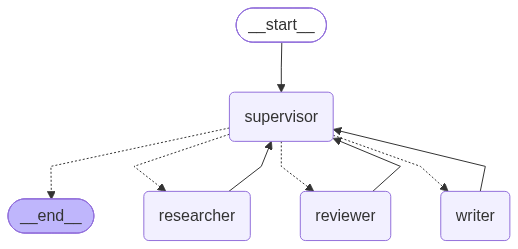

In [ ]:
g = StateGraph(TeamState)
g.add_node("supervisor", supervise)
g.add_node("researcher", researcher)
g.add_node("writer", writer)
g.add_node("reviewer", reviewer)

#TODO build the edges
g.add_edge(START, "supervisor")
g.add_conditional_edges("supervisor", route)
g.add_edge("researcher", "supervisor")
g.add_edge("writer", "supervisor")
g.add_edge("reviewer", "supervisor")

# you can also add edges with the for loop


supervised = g.compile()
display(Image(supervised.get_graph().draw_mermaid_png()))

In [54]:
def fresh(question):
    return {"question": question, "findings": [], "report": "", "unsupported": [],
            "review": "", "gap": "", "next": "", "decisions": 0, "tokens": 0, "log": []}


def run(graph, question):
    start = time.time()
    out = graph.invoke(fresh(question), {"recursion_limit": 40})
    out["seconds"] = time.time() - start
    return out



In [ ]:
from langchain_core.rate_limiters import InMemoryRateLimiter

model.rate_limiter = InMemoryRateLimiter(requests_per_second=0.2, check_every_n_seconds=0.1, max_bucket_size=1)
# above is my addition bc it was taking too long to run and i hit limit in google api

sup = run(supervised, QUESTION)
print(" -> ".join(sup["log"]))
print(f"\ncoverage {rt.score_coverage(sup['report'], GOLD):.2f}   unsupported {sup['unsupported']}   "
      f"tokens {sup['tokens']:,}   seconds {sup['seconds']:.0f}   supervisor decisions {sup['decisions']}")
print(f"last review: {sup['review']}: {sup['gap']}")

supervisor->researcher -> researcher -> supervisor->writer -> writer -> supervisor->reviewer -> reviewer -> supervisor->done

coverage 0.25   unsupported []   tokens 22,666   seconds 193   supervisor decisions 4
last review: accept: The papers (2503.13657, 2510.23682, 2606.27409, 2504.05047, 2601.11903) fully support the claims and answer every part of the question.


In [59]:
from IPython.display import Markdown

display(Markdown(sup["report"]))

# Reliability and Failures in Multi-Agent LLM Systems: A Research Report

Multi-agent Large Language Model systems (MAS) hold the promise of solving complex, multi-step tasks by distributing workloads across collaborating agents. However, these systems often exhibit minimal performance gains over single-agent setups due to distinct failure modes [2503.13657]. Below is an overview of why these systems fail, the architectures and methods proposed to improve their reliability, and how they are evaluated.

---

## 1. Why Multi-Agent LLM Systems Fail

Multi-agent LLM systems are prone to a wide range of breakdowns. A comprehensive taxonomy classifies these failures into three primary categories: (i) system design issues, (ii) inter-agent misalignment, and (iii) task verification failures [2503.13657]. 

Specific breakdown mechanisms include:
* **Coordination and Communication Bottlenecks:** Systems frequently suffer from poor routing protocols, as well as difficulties in coordinating parallel tasks and managing shared payloads [2412.05449, 2503.13657].
* **Reasoning and Error Propagation:** Agents experience reasoning breakdowns and error propagation across sequential steps [2503.13657]. 
* **Verification Deficits:** Systems often lack the ability to correctly verify or validate both intermediate and final outputs [2503.13657].

---

## 2. Proposed Architectures and Methods for Reliability

To address catastrophic brittleness, opaque prompt sequences, and verification latencies, recent research has introduced several structural architectures and verification methods:

* **Neuro-Symbolic-Causal Architectures:** These integrate formal constraints and causal logic directly into agent control flows to combat the opaque nature of unstructured prompt sequences [2510.23682].
* **Optimal Corrector Placement and Cognitive Loops:** To mitigate hallucination propagation caused by verification latency, systems employ optimal corrector placement alongside structured cognitive loops to monitor belief stability across agent networks [2606.27409].
* **Adaptive Multi-Agent Collaboration:** To prevent excessive computational overhead while controlling errors, frameworks implement adaptive collaboration—such as triggering debates or verifications only when specific uncertainty thresholds are crossed [2504.05047].
* **Verifiable Evaluation and Control Frameworks:** Frameworks such as AEMA are deployed to systematically audit agentic coordination, transparency, and runtime behavior [2601.11903].

---

## 3. Metrics, Benchmarks, and Comparisons

Evaluating multi-agent LLM systems requires moving past traditional single-response scoring to capture interactive dynamics, emergent behaviors, and verifiable coordination [2601.11903, 2506.03053].

* **Metrics & Frameworks:** Process-aware and auditable frameworks (e.g., AEMA) evaluate multi-step workflows by tracking coordination stability, human alignment, and traceable decision trails [2601.11903]. Safety evaluations also utilize specialized techniques, such as double-inversion question formatting, to measure moral preferences like instrumental harm [2506.03053].
* **Benchmarks:** Systems are tested using interactive environments such as the Greatest Good Benchmark, alongside simulated enterprise business workflows [2506.03053, 2601.11903].
* **Comparisons:** Comparative evaluations between isolated LLMs and multi-agent ensembles reveal that group dynamics—such as peer pressure and convergence under supervision—produce emergent moral reasoning and failure modes that cannot be predicted by analyzing single-agent behavior alone [2506.03053].

## 4. Three requests, three paths

The run above was a summary request, so the supervisor sent all three agents. The supervisor's first decision, though, depends on the request.

Run the same team on three kinds of request and compare the paths it chooses. The summary request takes as long as the run above; the other two are short.

In [60]:
REQUESTS = ["Which paper introduced the MAST taxonomy of multi-agent failures?",
            "Summarize what is known about why multi-agent LLM systems fail.",
            "Check this claim: multi-agent debate improves accuracy on GSM8K [2305.14325]."]

for request in REQUESTS:
    out = run(supervised, request)
    result = out["report"] or (f"{out['review']}: {out['gap']}" if out["review"] else team.format_findings(out["findings"]))
    print(request)
    print("  path:", " -> ".join(e for e in out["log"] if not e.startswith("supervisor")))
    print("  result:", result[:300], "\n")


Which paper introduced the MAST taxonomy of multi-agent failures?
  path: researcher
  result: Sub-question: Which paper introduced the MAST taxonomy of multi-agent failures proposing main systems or methods?
The MAST taxonomy of multi-agent failures was introduced by Cemri et al. (2025) in their study on why multi-agent LLM systems fail [2503.13657]. To build the Multi-Agent System Failure T 

Summarize what is known about why multi-agent LLM systems fail.
  path: researcher -> writer -> reviewer
  result: ### Main Multi-Agent LLM Systems and Methods

Research into multi-agent Large Language Model (LLM) systems has primarily focused on methods incorporating structured communication, role assignment, and workflow automation. Notable frameworks include:

*   **AutoGen:** A foundational open-source frame 



KeyboardInterrupt: 

Compare the three paths. The team and its agents are the same for every request, but the paths differ, because the supervisor read each request and chose the agents it needed.

A fixed graph would run one path for all three: it would either research and write a report for a request that only needed a paper's name, or have no way to check a claim. This is the decision a supervisor is for: one that depends on the content of the request, and cannot be written down in advance.

## 5. MAST on your own trace

Print the trace of the supervisor's run and find two failures. For each, say which of the taxonomy's groups it belongs to: **specification** (the task or the roles were under-described), **inter-agent misalignment** (an agent did its job on the wrong input, or ignored what another agent produced), or **verification** (something wrong got through, or something right got rejected).

In [61]:
print(" -> ".join(sup["log"]))
print(f"\nunsupported after the writer's check: {sup['unsupported']}")
print(f"last review: {sup['review']}: {sup['gap']}")
print(f"findings: {len(sup['findings'])}")
for q, _ in sup["findings"]:
    print("  -", q)

supervisor->researcher -> researcher -> supervisor->writer -> writer -> supervisor->reviewer -> reviewer -> supervisor->done

unsupported after the writer's check: []
last review: accept: The papers (2503.13657, 2510.23682, 2606.27409, 2504.05047, 2601.11903) fully support the claims and answer every part of the question.
findings: 3
  - What specific problems and failures have been reported in multi-agent LLM systems?
  - What main architectures and methods have been proposed to make multi-agent LLM systems more reliable?
  - What metrics, benchmarks, and comparisons have been used to evaluate the reliability and performance of multi-agent LLM systems?


## 6. Things to try

1. Delete the list of request kinds from the supervisor's prompt, keeping the agent descriptions and the rules for after the reviewer. Run the three requests again. Does the supervisor still choose the right agents? When it does not, which MAST group is that?

2. Replace the reviewer agent with a single model call that reads the report and the question and has no tools. Compare its notes with the agent's notes. Which one names specific missing papers?

3. Remove the citation check from the writer, so it returns its first draft. Compare `unsupported` with and without the check, and what the check costs in tokens.

4. Set `MAX_DECISIONS` to 4. Which agent does the cap cut off, and what does the final report look like?

5. Run the team on another question in `rt.questions()`. Does the reviewer ask for research, and does coverage go up when it does?

In [ ]:
# your experiments here